## Finetune a ViT model on the Food 101 dataset

> What accuray can you reach how about using a CLIP model, zero-shot?


### PLAN 
> 1. Import and explore a bit the data
> 2. Process, standardize and tokenize, also don't forget that we need a data collator
> 3. Choose a metric (example accuracy) 
> 4. Choose a model
> 5. Train the model

In [1]:
#PyTorch Libraries
import torchvision
import torch
from torch.utils.data import random_split, DataLoader

#Hugging Face Libraries
from transformers import (AutoImageProcessor, AutoModelForImageClassification, TrainingArguments,
                          Trainer,CLIPTokenizer, CLIPImageProcessor, AutoModelForZeroShotImageClassification)

#Scikit-Learn
from sklearn.metrics import accuracy_score

import inspect
import gc


In [2]:
food101_dataset = torchvision.datasets.Food101("datasets", download=True, split="train")
food101_dataset_test = torchvision.datasets.Food101("datasets", download=True, split="test")

In [3]:
food101_dataset_test[10]

(<PIL.Image.Image image mode=RGB size=512x306>, 23)

In [4]:
food101_data_test, food101_data_validation = random_split(food101_dataset_test, [5250, 20000])

In [5]:
food101_dataset_test.__len__()

25250

In [6]:
len(food101_dataset.classes)

101

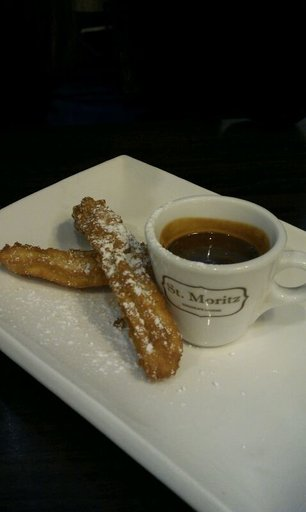

In [7]:
food101_dataset[0][0]
food101_dataset[12][0]

In [8]:
type(food101_dataset)

torchvision.datasets.food101.Food101

In [9]:
processor = AutoImageProcessor.from_pretrained("google/vit-base-patch16-224")
model = AutoModelForImageClassification.from_pretrained("google/vit-base-patch16-224", device_map="auto", num_labels=101, ignore_mismatched_sizes=True)

[transformers] You passed `num_labels=101` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                            
------------------+----------+--------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([101])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([101, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


In [18]:
def collate_fn(batch):
    images = [image[0] for image in batch]
    labels = [image[1] for image in batch]
    inputs = processor(images, return_tensors="pt", do_convert_rgb=True)
    inputs['labels'] = torch.tensor(labels)
    return inputs

In [19]:
collate_fn([food101_dataset[1], food101_dataset[2]])

{'pixel_values': tensor([[[[ 0.8980,  0.9059,  0.8902,  ...,  0.7412,  0.7098,  0.6392],
          [ 0.8902,  0.8980,  0.8902,  ...,  0.7333,  0.7020,  0.6471],
          [ 0.8980,  0.9059,  0.9137,  ...,  0.7255,  0.7176,  0.7020],
          ...,
          [ 0.6314,  0.6471,  0.6471,  ...,  0.2157,  0.2157,  0.2157],
          [ 0.6235,  0.6471,  0.6784,  ...,  0.2314,  0.2314,  0.2078],
          [ 0.6235,  0.6549,  0.6941,  ...,  0.2078,  0.1529,  0.1529]],

         [[ 0.9059,  0.9137,  0.9059,  ...,  0.8431,  0.8118,  0.7412],
          [ 0.8980,  0.9059,  0.9059,  ...,  0.8353,  0.8039,  0.7490],
          [ 0.9059,  0.9137,  0.9216,  ...,  0.8275,  0.8196,  0.8039],
          ...,
          [ 0.7490,  0.7412,  0.7333,  ...,  0.2235,  0.2235,  0.2235],
          [ 0.7412,  0.7490,  0.7569,  ...,  0.2392,  0.2392,  0.2157],
          [ 0.7412,  0.7569,  0.7725,  ...,  0.2157,  0.1608,  0.1608]],

         [[ 0.9216,  0.9216,  0.8980,  ...,  0.8902,  0.8667,  0.8039],
          [ 0

In [9]:
def compute_accuracy(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)
    return {"accuracy" : accuracy_score(labels, preds)}

In [21]:
trainingARGS = TrainingArguments(
    "food_101_model", per_device_train_batch_size=32, num_train_epochs=4,
    warmup_steps=100, eval_strategy='epoch', save_strategy='epoch'
)

In [22]:
trainer = Trainer(model, trainingARGS, collate_fn, food101_dataset, food101_data_validation, compute_metrics=compute_accuracy)

In [23]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,0.680250,0.462390,0.875000
2,0.313532,0.390946,0.890700
3,0.108755,0.398738,0.893400
4,0.032183,0.396645,0.898950


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=9472, training_loss=0.3923879922241778, metrics={'train_runtime': 2775.2443, 'train_samples_per_second': 109.18, 'train_steps_per_second': 3.413, 'total_flos': 2.35009068553728e+19, 'train_loss': 0.3923879922241778, 'epoch': 4.0})

In [24]:
trainer.predict(food101_data_test)

PredictionOutput(predictions=array([[-2.884153  ,  0.15034804, -0.5866064 , ..., -1.4540479 ,
         1.7930295 , -0.52588266],
       [-1.4098815 , -1.2131785 , -0.4227561 , ..., -0.6342771 ,
        -0.16430466, -1.8016099 ],
       [ 3.119436  , -1.7103403 , 13.436605  , ...,  0.9471587 ,
        -0.7040645 , -1.1449553 ],
       ...,
       [-0.6674564 , -0.6813657 ,  1.0773882 , ...,  0.77807665,
         1.240789  , -0.4627802 ],
       [-0.9800394 , -0.36723807, -0.97511923, ..., -0.5289961 ,
         8.646832  , -0.9999836 ],
       [ 0.1338525 , -1.3220928 , -0.5356819 , ..., -1.6407549 ,
         0.5902396 , -1.4839238 ]], shape=(5250, 101), dtype=float32), label_ids=array([82, 26,  2, ..., 25, 99, 85], shape=(5250,)), metrics={'test_loss': 0.4112154543399811, 'test_accuracy': 0.8956190476190476, 'test_runtime': 18.4748, 'test_samples_per_second': 284.171, 'test_steps_per_second': 35.562})

# Comparing with CLIP - zero shot classification

In [9]:
model_id = "openai/clip-vit-base-patch32"

clip_text_tokenizer = CLIPTokenizer.from_pretrained(model_id)
clip_image_tokenizer = CLIPImageProcessor.from_pretrained(model_id)
clip_model = AutoModelForZeroShotImageClassification.from_pretrained(model_id, device_map="auto", num_labels=101)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

In [10]:
food101_classes = food101_dataset.classes
type(food101_classes)

list

In [11]:
food101_data_test.dataset[0]

(<PIL.Image.Image image mode=RGB size=512x512>, 23)

In [12]:
food101_data_test.__len__()

5250

In [13]:
def as_tensor(out):
    return out if torch.is_tensor(out) else out.pooler_output

In [20]:
#print(type(one_example))
#Get the represenation of the labels
with torch.no_grad():
    captions = [f"This is a photo of {label}, a type of food" for label in food101_classes]
    inputs = clip_text_tokenizer(text=captions, return_tensors="pt",padding=True).to('cuda')
    label_representation = as_tensor(clip_model.get_text_features(**inputs))
    label_representation /= label_representation.norm(dim=-1, keepdim=True)


In [15]:
torch.cuda.memory_allocated()

638896128

In [16]:
def collate_for_clip(batch):
    imgs, labels = zip(*batch)
    inputs = clip_image_tokenizer(images=list(imgs), return_tensors="pt")
    return inputs, torch.tensor(labels)

In [17]:
test_loader = DataLoader(food101_data_test, collate_fn=collate_for_clip, batch_size = 64)

In [21]:
def as_tensor(out):
    return out if torch.is_tensor(out) else out.pooler_output

correct = total = 0
for image, label in test_loader:
    image = image.to("cuda")
    label = label.to("cuda")
    image_representation = as_tensor(clip_model.get_image_features(**image))
    image_representation = image_representation/ image_representation.norm(dim=-1, keepdim=True)
    preds = (image_representation @ label_representation.T).argmax(dim=-1)
    correct += (preds ==label).sum().item()
    total +=label.size(0)

In [22]:
f"{correct / total:.2%}"

'83.10%'

In [23]:
print(type(clip_model.get_text_features(**inputs)))

<class 'transformers.modeling_outputs.BaseModelOutputWithPooling'>
